# Case CIDACS — Notebook 1: Análise Exploratória

**Pergunta do case:** para cada um dos 100 endereços da base de busca, qual é o setor
censitário correspondente no CNEFE Bahia?

Este notebook **não resolve** o case. Ele responde a uma pergunta anterior: *como os dados
realmente são?* Cada achado aqui vira uma regra obrigatória de normalização no Notebook 2.

Rodar na ordem. Cada seção é independente e imprime a evidência que sustenta a conclusão.

## 0. Ambiente e caminhos

Prepara a sessão: importa as bibliotecas, descobre a raiz do projeto (o notebook funciona
tanto rodando de `notebooks/` quanto da raiz) e fixa os caminhos das bases. Nada é lido ainda —
é só o terreno para as seções seguintes.

In [1]:
import os
import sys
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = RAIZ / "data" / "raw"
sys.path.insert(0, str(RAIZ / "src"))

CNEFE_CSV = RAW / "29_BA.csv"
CACHE_EDA = RAIZ / "data" / "cache_eda.parquet"      # só para esta exploração

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
con = duckdb.connect()

print("raiz:", RAIZ)
print("pandas", pd.__version__, "| duckdb", duckdb.__version__)

raiz: /home/carol/Área de trabalho/[LACEDA]Case1
pandas 3.0.6 | duckdb 1.5.6


## 1. O que existe em `data/raw`

Lista os arquivos de entrada e seus tamanhos, antes de qualquer análise. Serve para saber
com o que estamos lidando de fato e para deixar explícito o que ainda está faltando baixar.

In [2]:
for arquivo in sorted(RAW.glob("*")):
    print(f"{arquivo.name:<35} {arquivo.stat().st_size / 1e6:>10.1f} MB")

29_BA.csv                               1461.7 MB
COMO_OBTER_OS_DADOS.md                     0.0 MB


A base de busca (100 endereços) fica no SharePoint da Fiocruz e responde **HTTP 403** sem
login — precisa ser baixada manualmente para `data/raw/`. As seções 2 a 9 tratam do CNEFE e
rodam sem ela; a seção 10 só roda quando ela aparecer.

## 2. Um cache local para explorar

Este notebook faz ~15 varreduras na tabela inteira, e na prática você re-roda célula o tempo
todo enquanto explora. Cada varredura do CSV de 1,46 GB custa ~13 s; do mesmo dado em Parquet,
~4 s. Converto uma vez e trabalho em cima disso.

**Isto é conveniência de exploração, não arquitetura.** O pipeline da solução
(`02_pipeline_plano_simples.ipynb` e `src/main.py`) lê o CSV original direto, sem camada
intermediária — lá a varredura acontece uma vez só e o cache não se pagaria.

**Tudo é lido como texto.** `COD_SETOR`, `CEP` e `COD_MUNICIPIO` têm zeros à esquerda
significativos — lidos como número, viram outra coisa.

In [3]:
COLUNAS_UTEIS = [
    "COD_UNICO_ENDERECO", "COD_MUNICIPIO", "COD_SETOR", "CEP", "DSC_LOCALIDADE",
    "NOM_TIPO_SEGLOGR", "NOM_TITULO_SEGLOGR", "NOM_SEGLOGR", "NUM_ENDERECO",
    "DSC_MODIFICADOR", "LATITUDE", "LONGITUDE",
]

if not CACHE_EDA.exists():
    con.execute(f'''
        COPY (
            SELECT {", ".join(COLUNAS_UTEIS)}
            FROM read_csv_auto('{CNEFE_CSV}', delim=';', header=true, all_varchar=true)
        ) TO '{CACHE_EDA}' (FORMAT PARQUET, COMPRESSION ZSTD)
    ''')
    print("cache gerado")
else:
    print("cache já existe — reaproveitando")

CNEFE = f"'{CACHE_EDA}'"
print(f"{CACHE_EDA.stat().st_size / 1e6:.0f} MB")

cache já existe — reaproveitando
257 MB


### 2.1 Schema completo do CSV original (34 colunas)

Pergunta ao próprio arquivo quais são suas colunas, em vez de confiar na documentação. É a
lista completa das 34 colunas do CNEFE — dela saíram as 12 que o pareamento de endereço usa.

In [4]:
schema = con.execute(f'''
    DESCRIBE SELECT * FROM read_csv_auto('{CNEFE_CSV}', delim=';', header=true,
                                         all_varchar=true, sample_size=1000)
''').df()
print(f"{len(schema)} colunas")
print(" · ".join(schema["column_name"]))

34 colunas
COD_UNICO_ENDERECO · COD_UF · COD_MUNICIPIO · COD_DISTRITO · COD_SUBDISTRITO · COD_SETOR · NUM_QUADRA · NUM_FACE · CEP · DSC_LOCALIDADE · NOM_TIPO_SEGLOGR · NOM_TITULO_SEGLOGR · NOM_SEGLOGR · NUM_ENDERECO · DSC_MODIFICADOR · NOM_COMP_ELEM1 · VAL_COMP_ELEM1 · NOM_COMP_ELEM2 · VAL_COMP_ELEM2 · NOM_COMP_ELEM3 · VAL_COMP_ELEM3 · NOM_COMP_ELEM4 · VAL_COMP_ELEM4 · NOM_COMP_ELEM5 · VAL_COMP_ELEM5 · LATITUDE · LONGITUDE · NV_GEO_COORD · COD_ESPECIE · DSC_ESTABELECIMENTO · COD_INDICADOR_ESTAB_ENDERECO · COD_INDICADOR_CONST_ENDERECO · COD_INDICADOR_FINALIDADE_CONST · COD_TIPO_ESPECI


### 2.2 Primeiras linhas

Olha cinco linhas de verdade. Ver o dado com os próprios olhos antes de agregá-lo costuma
revelar em segundos coisas que nenhuma estatística mostra — como o sufixo `P` do setor.

In [5]:
con.execute(f"SELECT * FROM {CNEFE} LIMIT 5").df()

,COD_UNICO_ENDERECO,COD_MUNICIPIO,COD_SETOR,CEP,DSC_LOCALIDADE,NOM_TIPO_SEGLOGR,NOM_TITULO_SEGLOGR,NOM_SEGLOGR,NUM_ENDERECO,DSC_MODIFICADOR,LATITUDE,LONGITUDE
0,112026678,2900801,290080125000007P,45910000,POUSO ALEGRE,BAIXA,NaN,SEM DENOMINACAO,0,SN,-17.421301,-39.588591
1,112026678,2900801,290080125000007P,45910000,POUSO ALEGRE,BAIXA,NaN,SEM DENOMINACAO,0,SN,-17.421301,-39.588591
2,192615207,2901007,290100705000002P,45300000,AMARGOSA,AVENIDA,DOUTOR,ABELARDO VELOSO,776,NaN,-13.030280,-39.595209
3,24076305,2901007,290100705000029P,45300000,LAGOA QUEIMADA,POVOADO,NaN,LAGOA QUEIMADA,17,NaN,-12.976211,-39.577448
4,192618976,2901007,290100705000045P,45300000,SANTA RITA,TRAVESSA,NaN,QUINTA LUIS SANDE,0,SN,-13.016349,-39.608956


## 3. Volumetria

Mede o tamanho do problema: quantos endereços, municípios, setores e CEPs existem. Esses
números decidem a estratégia — é o que diz se a base cabe em memória ou se precisa de recorte.

In [6]:
con.execute(f'''
    SELECT COUNT(*)                        AS linhas,
           COUNT(DISTINCT COD_MUNICIPIO)   AS municipios,
           COUNT(DISTINCT COD_SETOR)       AS setores,
           COUNT(DISTINCT CEP)             AS ceps
    FROM {CNEFE}
''').df()

,linhas,municipios,setores,ceps
0,9047296,417,30506,45472


9,0 milhões de endereços, 417 municípios (toda a Bahia), 30,5 mil setores censitários.

Cabe em memória? Não inteiro — mas **não precisa**. São só 100 consultas, concentradas em
poucos municípios. O recorte por município (*blocking*) resolve, e é o que o Notebook 2 faz.

## 4. 🔑 `COD_SETOR` tem um sufixo `P`

O enunciado mostra `292740805000123` — 15 dígitos. Vejamos o que o CNEFE traz.

In [7]:
con.execute(f'''
    SELECT LENGTH(COD_SETOR)                        AS tamanho,
           RIGHT(COD_SETOR, 1)                      AS ultimo_char,
           COUNT(*)                                 AS linhas,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM {CNEFE}
    GROUP BY 1, 2 ORDER BY linhas DESC
''').df()

,tamanho,ultimo_char,linhas,pct
0,16,P,9047296,100.0


In [8]:
con.execute(f'''
    SELECT COD_SETOR AS cnefe, LEFT(COD_SETOR, 15) AS formato_do_enunciado
    FROM {CNEFE} LIMIT 3
''').df()

,cnefe,formato_do_enunciado
0,290080125000007P,290080125000007
1,290080125000007P,290080125000007
2,290100705000002P,290100705000002


**Regra 1 (obrigatória):** `setor_15 = COD_SETOR[:15]`.

Em 100% das 9.047.296 linhas o código tem 16 caracteres e termina em `P`. Sem esse corte,
nenhum setor devolvido bate com o formato esperado na entrega.

## 5. 🔑 Código de município: 7 dígitos aqui, 6 na base de busca

O enunciado mostra `consulta_municipio = 290070` (Alagoinhas) e `290130` (Andaraí).

In [9]:
con.execute(f'''
    SELECT LENGTH(COD_MUNICIPIO) AS tamanho, COUNT(*) AS linhas
    FROM {CNEFE} GROUP BY 1
''').df()

,tamanho,linhas
0,7,9047296


In [10]:
# os dois municípios do exemplo do enunciado, localizados pelo CEP
con.execute(f'''
    SELECT CEP, COD_MUNICIPIO,
           LEFT(COD_MUNICIPIO, 6) AS municipio_6_digitos,
           COUNT(*)               AS enderecos
    FROM {CNEFE}
    WHERE CEP IN ('48030260', '46830000')
    GROUP BY 1, 2, 3
''').df()

,CEP,COD_MUNICIPIO,municipio_6_digitos,enderecos
0,46830000,2901304,290130,8642
1,48030260,2900702,290070,406


**Regra 2 (obrigatória):** juntar os dois lados por `COD_MUNICIPIO[:6]`.

O 7º dígito do IBGE é o verificador — a base de busca o omite. Se isso passar despercebido,
o blocking por município falha em **100%** dos casos e nenhum match acontece.

## 6. 🔑 O logradouro está quebrado em 3 colunas

A base de busca traz `consulta_logradouro` com tudo junto. O CNEFE separa tipo, título e nome.

In [11]:
con.execute(f'''
    SELECT NOM_TIPO_SEGLOGR AS tipo, NOM_TITULO_SEGLOGR AS titulo,
           NOM_SEGLOGR AS nome,
           TRIM(CONCAT_WS(' ', NOM_TIPO_SEGLOGR, NOM_TITULO_SEGLOGR, NOM_SEGLOGR)) AS composto
    FROM {CNEFE}
    WHERE NOM_TITULO_SEGLOGR IS NOT NULL AND NOM_TITULO_SEGLOGR <> ''
    LIMIT 8
''').df()

,tipo,titulo,nome,composto
0,AVENIDA,DOUTOR,ABELARDO VELOSO,AVENIDA DOUTOR ABELARDO VELOSO
1,RUA,MINISTRO,LIMA TEIXEIRA,RUA MINISTRO LIMA TEIXEIRA
2,RUA,NOSSA SENHORA,APARECIDA,RUA NOSSA SENHORA APARECIDA
3,RUA,NOSSA SENHORA,APARECIDA,RUA NOSSA SENHORA APARECIDA
4,PRACA,SENHOR,DA ASCENCAO,PRACA SENHOR DA ASCENCAO
5,RUA,DOUTOR,CLAUDIONOR OLIVEIRA,RUA DOUTOR CLAUDIONOR OLIVEIRA
6,RUA,DOUTOR,CLAUDIONOR OLIVEIRA,RUA DOUTOR CLAUDIONOR OLIVEIRA
7,RUA,CARDEAL,DA SILVA,RUA CARDEAL DA SILVA


### 6.1 Vocabulário real de tipos de logradouro

Conta quais tipos de logradouro realmente aparecem, e em que volume. É daqui que sai a lista
de abreviações a cobrir: o dicionário tem de atender ao vocabulário real da base, não ao que
imaginamos que uma base de endereços contém.

In [12]:
tipos = con.execute(f'''
    SELECT NOM_TIPO_SEGLOGR AS tipo, COUNT(*) AS enderecos
    FROM {CNEFE} GROUP BY 1 ORDER BY enderecos DESC LIMIT 20
''').df()
tipos

,tipo,enderecos
0,RUA,4818805
1,ESTRADA,983394
2,FAZENDA,664661
3,AVENIDA,651028
4,TRAVESSA,475648
5,POVOADO,367136
6,PRACA,123690
7,CAMINHO,120021
8,RODOVIA,101908
9,SITIO,54481


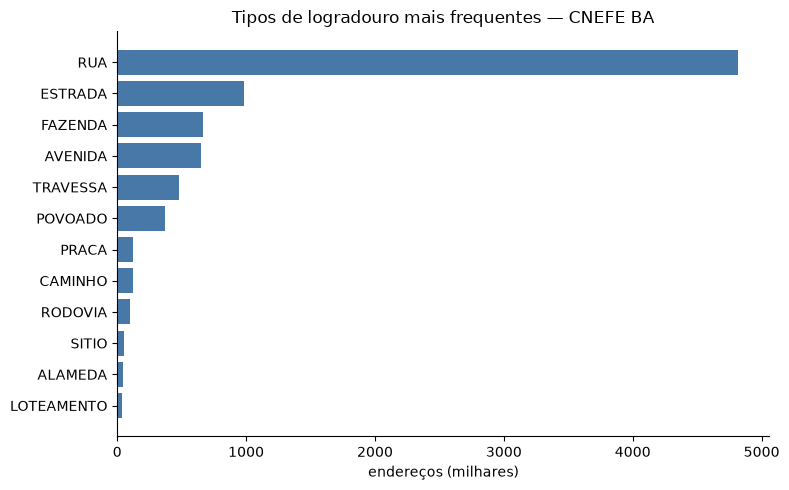

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
top = tipos.head(12).iloc[::-1]
ax.barh(top["tipo"], top["enderecos"] / 1e3, color="#4878a8")
ax.set_xlabel("endereços (milhares)")
ax.set_title("Tipos de logradouro mais frequentes — CNEFE BA")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Consequência para o dicionário de abreviações:** a Bahia é majoritariamente rural na
contagem de endereços. `FAZENDA` (665 mil), `POVOADO` (367 mil) e `SITIO` (54 mil) estão entre
os tipos mais comuns. Um dicionário que cubra só `RUA`/`AVENIDA`/`PRAÇA` deixa mais de um
milhão de endereços de fora.

## 7. 🔑 29% dos endereços não têm número

"Sem número" é codificado em **duas** colunas ao mesmo tempo.

In [14]:
con.execute(f'''
    SELECT CASE WHEN NUM_ENDERECO = '0' THEN 'NUM_ENDERECO = 0'
                ELSE 'número real' END                                                 AS numero,
           CASE WHEN DSC_MODIFICADOR = 'SN' THEN 'DSC_MODIFICADOR = SN'
                ELSE 'outro / vazio' END                                               AS modificador,
           COUNT(*)                                                                    AS linhas,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)                          AS pct
    FROM {CNEFE}
    GROUP BY 1, 2 ORDER BY linhas DESC
''').df()

,numero,modificador,linhas,pct
0,número real,outro / vazio,6392541,70.7
1,NUM_ENDERECO = 0,DSC_MODIFICADOR = SN,2654755,29.3


**Regra 3:** `NUM_ENDERECO = '0'` e `DSC_MODIFICADOR = 'SN'` andam sempre juntos — 2,65 milhões
de linhas (29%).

**Consequência para a estratégia de busca:** a cascata **não pode depender do número**. Quase
um terço da base de referência não tem número para comparar, e a base de busca também traz
`S/N`. Por isso existem níveis que casam só por CEP + logradouro.

## 8. Qualidade do CEP do lado CNEFE

Verifica se o CEP do CNEFE precisa de limpeza, checando tamanho e presença de caracteres
não numéricos. O resultado define se a normalização de CEP precisa agir nos dois lados ou só
no lado da base de busca.

In [15]:
con.execute(f'''
    SELECT LENGTH(CEP)                                  AS tamanho,
           COUNT(*)                                     AS linhas,
           SUM(CASE WHEN CEP ~ '^[0-9]+$' THEN 0 ELSE 1 END) AS com_caractere_nao_digito
    FROM {CNEFE} GROUP BY 1 ORDER BY linhas DESC
''').df()

,tamanho,linhas,com_caractere_nao_digito
0,8,9047296,0.0


100% com 8 dígitos, sem máscara, sem nulo. **A sujeira de CEP virá apenas da base de busca** —
é lá que aparecem `48030-260`, `8030260` (zero à esquerda comido pelo Excel) e vazios.

## 9. Poder discriminante do CEP — a justificativa da cascata

A pergunta que decide o desenho da solução: **um CEP sozinho identifica o setor?**

In [16]:
con.execute(f'''
    SELECT CEP,
           COUNT(*)                  AS enderecos,
           COUNT(DISTINCT COD_SETOR) AS setores_distintos
    FROM {CNEFE}
    WHERE CEP IN ('48030260', '46830000')
    GROUP BY 1
''').df()

,CEP,enderecos,setores_distintos
0,46830000,8642,38
1,48030260,406,1


`48030260` (Alagoinhas, urbano): 406 endereços, **1 setor** — o CEP resolve sozinho.
`46830000` (Andaraí): 8.642 endereços, **38 setores** — CEP genérico de município pequeno,
não resolve nada sozinho.

Dois CEPs, dois comportamentos opostos. Agora a distribuição completa.

In [17]:
dist = con.execute(f'''
    WITH por_cep AS (
        SELECT CEP, COUNT(DISTINCT COD_SETOR) AS setores
        FROM {CNEFE} WHERE CEP <> '' GROUP BY 1
    )
    SELECT CASE WHEN setores = 1 THEN '1 setor (resolve sozinho)'
                WHEN setores <= 5  THEN '2 a 5'
                WHEN setores <= 20 THEN '6 a 20'
                WHEN setores <= 50 THEN '21 a 50'
                ELSE 'mais de 50' END                       AS faixa,
           COUNT(*)                                          AS ceps,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM por_cep GROUP BY 1 ORDER BY ceps DESC
''').df()
dist

,faixa,ceps,pct
0,1 setor (resolve sozinho),27276,60.0
1,2 a 5,16256,35.7
2,6 a 20,1519,3.3
3,21 a 50,286,0.6
4,mais de 50,135,0.3


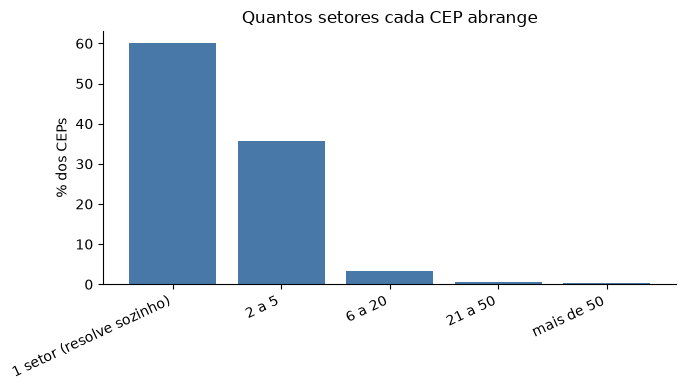

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
ordem = ["1 setor (resolve sozinho)", "2 a 5", "6 a 20", "21 a 50", "mais de 50"]
d = dist.set_index("faixa").reindex(ordem).dropna()
ax.bar(range(len(d)), d["pct"], color="#4878a8")
ax.set_xticks(range(len(d)))
ax.set_xticklabels(d.index, rotation=25, ha="right")
ax.set_ylabel("% dos CEPs")
ax.set_title("Quantos setores cada CEP abrange")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Conclusão que define a arquitetura:** não existe regra única que funcione. Em 60% dos CEPs,
município + CEP já entrega o setor sozinho; nos outros 40% é preciso descer até o logradouro
e, quando a escrita não bate, até a similaridade textual.

Daí a **busca em cascata** de 6 níveis do plano de trabalho — tentar do mais específico ao mais
tolerante, parando no primeiro que resolve, e registrando qual regra resolveu.

## 10. Base de busca — catálogo da sujeira

Só roda quando `data/raw/base_busca.xlsx` (ou `.csv`) existir. Esta seção é o que define
exatamente quais regras de limpeza o Notebook 2 precisa implementar.

In [19]:
candidatos = [p for p in RAW.glob("*")
              if p.suffix.lower() in {".xlsx", ".xls", ".csv"} and "29_BA" not in p.name]
if candidatos:
    arquivo = candidatos[0]
    busca = (pd.read_excel(arquivo, dtype=str) if arquivo.suffix.lower() != ".csv"
             else pd.read_csv(arquivo, dtype=str, sep=None, engine="python"))
    print(f"{arquivo.name}: {len(busca)} linhas × {len(busca.columns)} colunas")
    print(list(busca.columns))
else:
    busca = None
    print("base de busca ainda não baixada — seção 10 pulada")
    print("baixe do SharePoint (requer login) e salve em data/raw/")

base de busca ainda não baixada — seção 10 pulada
baixe do SharePoint (requer login) e salve em data/raw/


In [20]:
if busca is not None:
    display(busca.head(15))

### 10.1 Preenchimento por coluna

Mostra quanto de cada coluna vem preenchido e quantos valores distintos existem. É o retrato
de quais campos dá para confiar como chave de busca e quais vão faltar com frequência.

In [21]:
if busca is not None:
    vazio = busca.isna() | (busca.astype(str).apply(lambda c: c.str.strip()) == "")
    display(pd.DataFrame({
        "preenchidos": (~vazio).sum(),
        "vazios": vazio.sum(),
        "distintos": busca.nunique(dropna=True),
    }).sort_values("vazios", ascending=False))

### 10.2 Sujeira no CEP

Classifica os CEPs recebidos por padrão de escrita — limpos, com máscara, com dígitos
faltando, vazios — e mostra exemplos reais dos que fogem do formato. Cada padrão encontrado
vira uma regra em `normalizar_cep`.

In [22]:
if busca is not None:
    col_cep = next((c for c in busca.columns if "cep" in c.lower()), None)
    if col_cep:
        s = busca[col_cep].fillna("").astype(str).str.strip()
        display(pd.DataFrame({
            "padrao": ["8 dígitos limpos", "com máscara (-)", "menos de 8 dígitos",
                       "vazio", "outro"],
            "linhas": [
                s.str.fullmatch(r"\d{8}").sum(),
                s.str.contains("-").sum(),
                s.str.replace(r"\D", "", regex=True).str.len().between(1, 7).sum(),
                (s == "").sum(),
                (~s.str.fullmatch(r"[\d-]*")).sum(),
            ],
        }))
        display(s[~s.str.fullmatch(r"\d{8}")].head(10))

### 10.3 Abreviações e acentos no logradouro

Quantifica os tipos de variação de escrita presentes no logradouro: acento, ponto de
abreviação, caixa baixa, tipo de via abreviado. É a medida de quanto trabalho a normalização
de texto vai ter, e exibe as primeiras linhas para leitura direta.

In [23]:
if busca is not None:
    col_logr = next((c for c in busca.columns if "logr" in c.lower()
                     or "endereco" in c.lower()), None)
    if col_logr:
        s = busca[col_logr].fillna("").astype(str)
        import unicodedata
        tem_acento = s.map(lambda t: any(unicodedata.combining(c)
                                         for c in unicodedata.normalize("NFKD", t)))
        display(pd.DataFrame({
            "caracteristica": ["com acento", "com ponto final (R.)", "minúsculas",
                               "tipo abreviado no início", "vazio"],
            "linhas": [
                tem_acento.sum(),
                s.str.contains(r"\w\.", regex=True).sum(),
                (s != s.str.upper()).sum(),
                s.str.upper().str.match(r"^(R|AV|ROD|PC|PCA|TV|EST|AL)\b\.?\s").sum(),
                (s.str.strip() == "").sum(),
            ],
        }))
        display(s.head(20).to_frame())

### 10.4 Número e municípios presentes

Levanta como o "sem número" aparece na prática e quais municípios a busca envolve. A lista
de municípios é o insumo direto do recorte do Notebook 2 — só eles precisam ser carregados do
CNEFE.

In [24]:
if busca is not None:
    col_num = next((c for c in busca.columns if "num" in c.lower()), None)
    if col_num:
        display(busca[col_num].fillna("").astype(str).str.strip()
                .str.upper().value_counts().head(12).to_frame("linhas"))

    col_mun = next((c for c in busca.columns if "munic" in c.lower()), None)
    if col_mun:
        muns = busca[col_mun].dropna().astype(str).str.extract(r"(\d+)")[0].dropna().unique()
        print(f"{len(muns)} municípios distintos:", sorted(muns))
        print("\nSão esses — e só esses — que o Notebook 2 precisa carregar do CNEFE.")

## 11. Especificação do Notebook 2

O que esta exploração fixa como obrigatório:

| # | Achado | Regra que vira |
|---|---|---|
| 1 | `COD_SETOR` tem 16 chars terminando em `P` | `setor_15 = COD_SETOR[:15]` |
| 2 | Município: 7 dígitos no CNEFE, 6 na busca | juntar por `COD_MUNICIPIO[:6]` |
| 3 | Logradouro partido em 3 colunas | compor tipo + título + nome antes de comparar |
| 4 | Tipos rurais são massivos (FAZENDA, POVOADO, SITIO) | dicionário de abreviações cobre o rural |
| 5 | 29% sem número (`'0'` + `'SN'`) | cascata com níveis que ignoram o número |
| 6 | CEP limpo no CNEFE, sujo na busca | normalizar CEP só do lado da busca |
| 7 | Poder do CEP varia de 1 a 38 setores | busca em cascata, não regra única |
| 8 | Ler tudo como string | zeros à esquerda são significativos |

**Leitura como texto é inegociável.** `CEP`, `COD_SETOR` e `COD_MUNICIPIO` têm zeros à
esquerda; lidos como inteiro, o dado é destruído silenciosamente.

➡️ Seguir para `02_pipeline_plano_simples.ipynb`.